# Sprint 5 — Treinamento e avaliação do GPT

Capítulo 5 de RASCHKA, S. *Build a Large Language Model (From Scratch)*: como medir o erro de um modelo
de linguagem, como treiná-lo para reduzir esse erro, como escolher os tokens na geração e como salvar o
resultado.

## Roteiro

1. Dados de treinamento e validação
2. A perda de entropia cruzada, passo a passo
3. Perda e perplexidade do modelo sem treino
4. O laço de treinamento
5. Sobreajuste: treino × validação
6. Estratégias de geração com o mesmo contexto
7. Salvar, carregar e retomar

O código vem dos módulos do projeto (`src/treinamento.py`, `src/checkpoint.py`, `src/dados.py`); o notebook
só os executa e mostra o que acontece. Para caber em ~1 minuto, usa um **GPT reduzido** (`emb_dim = 256`,
4 blocos, 4 cabeças). O treino do GPT-2 124M completo está em
`experiments/sprint05-treinamento/treinar_base.py` e a análise em `reports/sprint05-relatorio.md`.

In [1]:
import math
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import torch

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

from checkpoint import carregar_checkpoint, retomar_treinamento, salvar_checkpoint
from dados import carregar_texto, criar_loaders_treino_validacao, dividir_treino_validacao
from geracao import gerar, ids_para_texto, texto_para_ids
from gpt import GPTModel, config_gpt2, contar_parametros
from tokenizacao import TokenizadorBPE
from treinamento import (ConfigTreinamento, avaliar_modelo, gerar_amostra, perda_do_lote,
                         perplexidade, treinar_modelo)

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
tok = TokenizadorBPE()
print("dispositivo:", DISPOSITIVO, "| torch", torch.__version__)

dispositivo: cuda | torch 2.14.1+cu126


## 1. Dados de treinamento e validação (seção 5.1)

O corpus é dividido em **90% para treino** e **10% para validação**, por caracteres e sem embaralhar: a
validação é um trecho contínuo do fim do conto, que o modelo nunca usa para ajustar os pesos. É a única
forma de saber se o modelo aprendeu algo geral ou só decorou o treino.

In [2]:
texto = carregar_texto()
treino, validacao = dividir_treino_validacao(texto, 0.9)
print(f"caracteres: {len(treino):,} treino + {len(validacao):,} validação = {len(texto):,}")
print(f"tokens    : {len(tok.encode(treino)):,} treino, {len(tok.encode(validacao)):,} validação")

torch.manual_seed(123)
loader_treino, loader_validacao = criar_loaders_treino_validacao(texto, batch_size=2, max_length=256, tokenizador=tok)
print(f"lotes     : {len(loader_treino)} de treino, {len(loader_validacao)} de validação")
x, y = next(iter(loader_treino))
print("forma de um lote:", tuple(x.shape), "| alvo = entrada deslocada:", bool((x[:, 1:] == y[:, :-1]).all()))

caracteres: 18,431 treino + 2,048 validação = 20,479
tokens    : 4,612 treino, 534 validação
lotes     : 9 de treino, 1 de validação
forma de um lote: (2, 256) | alvo = entrada deslocada: True


## 2. A perda de entropia cruzada, passo a passo

Para cada posição, o modelo devolve `V = 50.257` logits. A perda pega a probabilidade que o modelo deu ao
**token correto** e toma `−log`. Abaixo, o cálculo à mão em um exemplo minúsculo, comparado com
`torch.nn.functional.cross_entropy`.

In [3]:
logits = torch.tensor([[2.0, 1.0, 0.1],      # posição 1: o token certo é o 0
                       [0.5, 2.5, 0.3]])     # posição 2: o token certo é o 1
alvos = torch.tensor([0, 1])

probs = torch.softmax(logits, dim=-1)
p_correto = probs[torch.arange(2), alvos]
manual = -torch.log(p_correto).mean()
print("probabilidades do token correto:", p_correto.numpy().round(3))
print(f"perda manual = {manual:.4f} | cross_entropy = {torch.nn.functional.cross_entropy(logits, alvos):.4f}")

probabilidades do token correto: [0.659 0.802]
perda manual = 0.3185 | cross_entropy = 0.3185


## 3. Perda e perplexidade do modelo sem treino

Um modelo que distribui a probabilidade igualmente entre os `V` tokens tem perda `ln(V) ≈ 10,82` e
**perplexidade** `exp(perda) = V`: está "em dúvida" entre todos os tokens. É de perto disso que um modelo
recém-inicializado parte.

In [4]:
cfg = config_gpt2("small", context_length=256, emb_dim=256, n_heads=4, n_layers=4)
torch.manual_seed(123)
modelo = GPTModel(cfg).to(DISPOSITIVO)
print(f"parâmetros: {contar_parametros(modelo):,}")

perda_t, perda_v = avaliar_modelo(modelo, loader_treino, loader_validacao, DISPOSITIVO)
print(f"ln(V) = {math.log(cfg['vocab_size']):.2f}")
print(f"perda inicial: treino {perda_t:.2f} (perplexidade {perplexidade(perda_t):,.0f}) | "
      f"validação {perda_v:.2f} (perplexidade {perplexidade(perda_v):,.0f})")
print("amostra:", repr(gerar_amostra(modelo, "Every effort moves you", DISPOSITIVO, tok, 15)))

parâmetros: 28,953,600


ln(V) = 10.82
perda inicial: treino 11.00 (perplexidade 59,646) | validação 10.97 (perplexidade 57,901)


amostra: 'Every effort moves you hazardAND Mirrorcreation++++++++++++++++ternally unlawfully vowel masturb repeal condol masculriter Sor prisoner'


## 4. O laço de treinamento (seção 5.2)

Para cada época e cada lote, `treinar_modelo` faz:

1. `otimizador.zero_grad()` — apaga os gradientes do passo anterior;
2. `perda_do_lote(...)` — passagem direta e entropia cruzada;
3. `perda.backward()` — retropropagação: o gradiente da perda em cada peso;
4. `otimizador.step()` — o AdamW atualiza os pesos.

A cada 5 passos as perdas de treino e validação são medidas, e ao fim de cada época o modelo gera uma
amostra greedy a partir do **mesmo** contexto. Os parâmetros do treino ficam registrados em
`ConfigTreinamento`.

In [5]:
ct = ConfigTreinamento(num_epocas=10, taxa_aprendizado=4e-4, weight_decay=0.1, dispositivo=DISPOSITIVO)
print(ct.para_dict())

torch.manual_seed(123)
modelo = GPTModel(cfg).to(DISPOSITIVO)
otimizador = ct.criar_otimizador(modelo)
historico = treinar_modelo(modelo, loader_treino, loader_validacao, otimizador, DISPOSITIVO,
                           num_epocas=ct.num_epocas, frequencia_avaliacao=5, lotes_avaliacao=5,
                           contexto_inicial="Every effort moves you", tokenizador=tok, tokens_amostra=25)

{'num_epocas': 10, 'batch_size': 2, 'max_length': 256, 'stride': 256, 'proporcao_treino': 0.9, 'otimizador': 'AdamW', 'taxa_aprendizado': 0.0004, 'weight_decay': 0.1, 'frequencia_avaliacao': 5, 'lotes_avaliacao': 5, 'semente': 123, 'dispositivo': 'cuda', 'corpus': 'sprints/the-verdict.txt'}


  época   1 | passo     0 | perda treino 10.867 | perda validação 10.872


  época   1 | passo     5 | perda treino 10.087 | perda validação 10.195


  amostra (época 1): 'Every effort moves you, the,.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


  época   2 | passo    10 | perda treino 9.196 | perda validação 9.363


  época   2 | passo    15 | perda treino 8.447 | perda validação 8.677


... (19 outputs left out)

  época   9 | passo    80 | perda treino 5.090 | perda validação 6.327


  amostra (época 9): 'Every effort moves you, and, and.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


  época  10 | passo    85 | perda treino 4.939 | perda validação 6.301


  amostra (época 10): 'Every effort moves you, and, and.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


## 5. Sobreajuste: treino × validação

A perda de treino continua caindo; a de validação cai no começo e depois estaciona. Essa abertura é o
**sobreajuste**: com ~4.600 tokens de treino, o modelo passa a decorar o conto em vez de aprender
padrões gerais. A perplexidade (direita, escala log) mostra o mesmo em unidades de "tokens em dúvida".

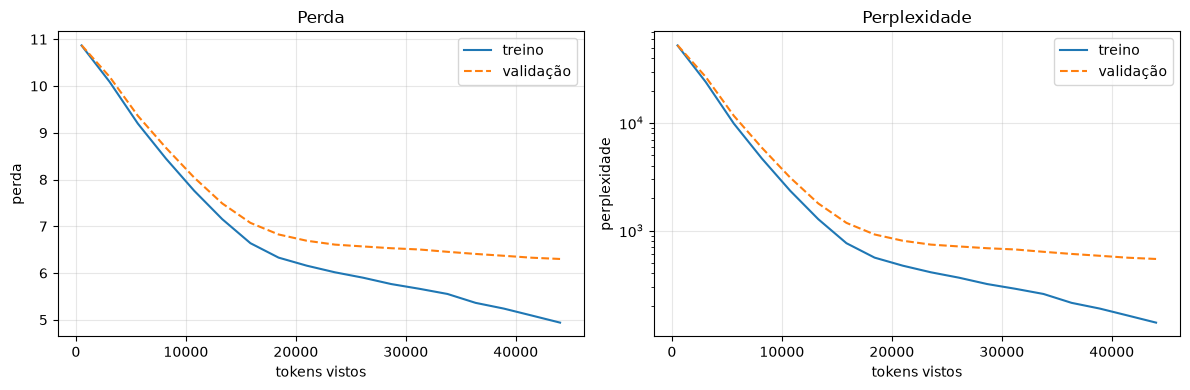

final: treino 4.86 (perplexidade 129.3) | validação 6.28 (perplexidade 536)
menor validação no histórico: 6.3


In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
t = historico["tokens_vistos"]
a1.plot(t, historico["perda_treino"], label="treino")
a1.plot(t, historico["perda_validacao"], "--", label="validação")
a1.set(xlabel="tokens vistos", ylabel="perda", title="Perda")
a2.plot(t, [perplexidade(p) for p in historico["perda_treino"]], label="treino")
a2.plot(t, [perplexidade(p) for p in historico["perda_validacao"]], "--", label="validação")
a2.set(xlabel="tokens vistos", ylabel="perplexidade", title="Perplexidade", yscale="log")
for a in (a1, a2):
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pt, pv = avaliar_modelo(modelo, loader_treino, loader_validacao, DISPOSITIVO)
print(f"final: treino {pt:.2f} (perplexidade {perplexidade(pt):.1f}) | validação {pv:.2f} (perplexidade {perplexidade(pv):.0f})")
print("menor validação no histórico:", round(min(historico['perda_validacao']), 2))

## 6. Estratégias de geração com o mesmo contexto (seção 5.3)

A estratégia de decodificação só escolhe **dentro** da distribuição que os pesos produzem. Com o mesmo
modelo e o mesmo contexto:

- **greedy** — sempre o mais provável: determinístico, tende a repetir o que foi decorado;
- **temperatura** < 1 concentra a distribuição, > 1 a achata (mais diversidade, menos coerência);
- **top-k** sorteia só entre os `k` mais prováveis, cortando os tokens absurdos.

A última célula repete as mesmas estratégias num modelo **sem treino**: aí nenhuma regra produz texto com
sentido — o que separa o efeito da decodificação do efeito do treinamento.

In [7]:
contexto = texto_para_ids("Every effort moves you", tok).to(DISPOSITIVO)
estrategias = [("greedy", 0.0, None), ("temperatura 0,5", 0.5, None), ("temperatura 1,0", 1.0, None),
               ("temperatura 2,0", 2.0, None), ("top-k 5", 1.0, 5), ("T=1,4 + top-k 25", 1.4, 25)]

def comparar(m, titulo):
    print(titulo)
    m.eval()
    for nome, temp, k in estrategias:
        torch.manual_seed(123)
        with torch.no_grad():
            saida = gerar(m, contexto, 25, cfg["context_length"], temperatura=temp, top_k=k)
        print(f"  {nome:<17} {ids_para_texto(saida, tok)!r}")

comparar(modelo, "Modelo treinado:")

Modelo treinado:


  greedy            'Every effort moves you, and, and.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


  temperatura 0,5   'Every effort moves you, as the of the me, I was the that, with a.\n\n" it.\n\n\n\n"'


  temperatura 1,0   'Every effort moves you as studio the felt to me because BoosterYes-- absurdity.\n\n\n between--I itpoke terr;fd flash I'


  temperatura 2,0   'Every effort moves you as studio wererow moderates meflower BoosterYes Participant absurdity reply2015ewskiivot fabric villain exhibited swordpoke terr righteousfd flash ankle'


  top-k 5           'Every effort moves you of his-- one to the, I was the that, with of the a--I.\n\n\n\n\n"'


  T=1,4 + top-k 25  'Every effort moves you of his the to my me, I was the that with a of.\n\n" it.\n\n\n\n I'


In [8]:
torch.manual_seed(123)
comparar(GPTModel(cfg).to(DISPOSITIVO), "Mesmo modelo, sem treino:")

Mesmo modelo, sem treino:


  greedy            'Every effort moves you hazardAND Mirrorcreation++++++++++++++++ternally unlawfully vowel masturb repeal condol masculriter Sor prisoner Cra YakCopy Treatyuild oddly huntsoshenko Wick Carolyn'


  temperatura 0,5   'Every effort moves you sociophareBritishPOS moderatesgovernmentensingenez clarify Participant cancellation Rocks2015 Marsivot fabricpora exhibitedKingfixfresh righteousfd luck ankle'


  temperatura 1,0   'Every effort moves you percentageshareBritishPOS moderatesgovernmentflowerenez enormous Participant cancellation reply2015 Marsivot fabric>>>> exhibited swordfix Trooper righteousfd luck ankle'


  temperatura 2,0   'Every effort moves you percentageshareBritishMaker moderates waveflowerenez enormous Participant pleasures reply2015 Marsivot fabric villain exhibited swordfixranch righteousfd luck ankle'


  top-k 5           'Every effort moves youilightchenExpl Priceswhich lay Similarly Prov comingclass$ Coca Overse loudspeminster DragonsKT Larson programsisionwal stars entered ammo Oblivion'


  T=1,4 + top-k 25  'Every effort moves you 237 Sexyinson afterliferuction richnessDesign convicted commerce repeal bulldo Average Bradfordave eclectic contemplatemore incub insistenceFLAG bloc anatomy withholding dear Pract'


## 7. Salvar, carregar e retomar (seção 5.4)

O checkpoint guarda os pesos (`state_dict`), o estado do AdamW, a configuração do modelo e a do treino.
Carregado, o modelo deve produzir **exatamente** os mesmos logits e o mesmo texto. Com o estado do
otimizador, o treino pode continuar como se nunca tivesse parado.

In [9]:
modelo.eval()
with torch.no_grad():
    logits_antes = modelo(contexto)
texto_antes = gerar_amostra(modelo, "Every effort moves you", DISPOSITIVO, tok, 20)

with tempfile.TemporaryDirectory() as pasta:
    caminho = salvar_checkpoint(Path(pasta) / "modelo.pt", modelo, otimizador, ct.para_dict(), historico)
    print(f"checkpoint: {caminho.stat().st_size / 1e6:.0f} MB")
    carregado, dados = carregar_checkpoint(caminho, DISPOSITIVO)
    with torch.no_grad():
        print("logits idênticos   :", torch.equal(carregado(contexto), logits_antes))
    print("mesma geração      :", gerar_amostra(carregado, "Every effort moves you", DISPOSITIVO, tok, 20) == texto_antes)
    print("configuração gravada:", {k: dados["cfg_modelo"][k] for k in ("emb_dim", "n_layers", "n_heads", "context_length")})

    retomado, opt_retomado, _ = retomar_treinamento(caminho, DISPOSITIVO)
    print("passos já dados pelo AdamW restaurado:", int(opt_retomado.state_dict()["state"][0]["step"]))

checkpoint: 348 MB


logits idênticos   : True


mesma geração      : True
configuração gravada: {'emb_dim': 256, 'n_layers': 4, 'n_heads': 4, 'context_length': 256}


passos já dados pelo AdamW restaurado: 90


## Resumo da Sprint 5

| Entregável | Onde |
|---|---|
| Avaliação: entropia cruzada, perplexidade, treino/validação | `src/treinamento.py`, `src/dados.py` |
| Rotina de treinamento | `treinar_modelo` em `src/treinamento.py` |
| Salvamento e carregamento | `src/checkpoint.py` |
| Validação (27 verificações) | `src/validar_treinamento.py` |
| Treino base e inferência do checkpoint | `experiments/sprint05-treinamento/treinar_base.py`, `gerar_com_checkpoint.py` |
| Experimentos E1–E6 | `experiments/sprint05-treinamento/` → `results-by-sprints/sprint05/` |
| Glossário | `technical-glossary/capitulo-05.md` |
| Análise | `reports/sprint05-relatorio.md` |